# Task 4 — Data Science Tool Mastery Project
**YuvaIntern · Data Analyst Internship** · **Intern:** Rashad kazi

**Objectives:** master industry-standard tools, demonstrate proficiency through practical exercises, and create portfolio pieces.

**Dataset:** Diabetes dataset (Efron, Hastie, Johnstone & Tibshirani, 2004, *Least Angle Regression*) — 442 patients, 10 baseline measurements, and a measure of disease progression one year later.

| Tool | Exercise | Portfolio piece |
|---|---|---|
| NumPy | Vectorisation, broadcasting, speed test | — |
| Pandas | Method chaining, binning, window and group transforms | `data/diabetes_features.csv` |
| SQL (SQLite) | Aggregation, CASE, window functions, sub-queries | `sql/diabetes_queries.sql` |
| Matplotlib + Seaborn | Chart gallery | `figures/` |
| SciPy | Hypothesis tests | — |
| scikit-learn | Pipelines, cross-validation, model comparison | Model results table |
| openpyxl | Automated, formatted Excel report with formulas and a chart | `output/Diabetes_Analysis_Report.xlsx` |
| Python modules | Reusable helper functions | `eda_toolkit.py` |
| Git & GitHub | Version control workflow | this repository |

In [1]:
import os, time, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import eda_toolkit as kit                     # my own reusable module

for d in ["figures", "data", "output", "sql"]:
    os.makedirs(d, exist_ok=True)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
RANDOM_STATE = 42

In [2]:
raw = load_diabetes(as_frame=True, scaled=False)
df = raw.frame.rename(columns={"s1": "total_chol", "s2": "ldl", "s3": "hdl", "s4": "chol_hdl_ratio",
                               "s5": "log_triglycerides", "s6": "glucose", "target": "progression"})
df["sex"] = df["sex"].map({1.0: "Group 1", 2.0: "Group 2"})
df.to_csv("data/diabetes_raw.csv", index=False)
kit.quick_profile(df)

Rows: 442 | Columns: 11 | Missing cells: 0 | Duplicate rows: 0
                     dtype  missing  unique      min    mean      max
age                float64        0      58  19.0000   48.52   79.000
bmi                float64        0     163  18.0000   26.38   42.200
bp                 float64        0     100  62.0000   94.65  133.000
chol_hdl_ratio     float64        0      66   2.0000    4.07    9.090
glucose            float64        0      56  58.0000   91.26  124.000
hdl                float64        0      63  22.0000   49.79   99.000
ldl                float64        0     302  41.6000  115.44  242.400
log_triglycerides  float64        0     184   3.2581    4.64    6.107
progression        float64        0     214  25.0000  152.13  346.000
sex                    str        0       2      NaN     NaN      NaN
total_chol         float64        0     141  97.0000  189.14  301.000


## Tool 1 — NumPy: vectorisation and broadcasting

In [3]:
bmi = df["bmi"].to_numpy()

start = time.perf_counter()
loop_z = [(x - bmi.mean()) / bmi.std() for x in bmi]          # Python loop
t_loop = time.perf_counter() - start

start = time.perf_counter()
vec_z = (bmi - bmi.mean()) / bmi.std()                         # vectorised
t_vec = time.perf_counter() - start
print(f"Same result: {np.allclose(loop_z, vec_z)} | loop {t_loop*1e3:.3f} ms vs vectorised {t_vec*1e3:.3f} ms")

# Broadcasting: standardise all numeric columns at once (442 x 9 matrix minus a 9-value vector)
X = df[["age", "bmi", "bp", "total_chol", "ldl", "hdl", "chol_hdl_ratio", "log_triglycerides", "glucose"]].to_numpy()
Z = (X - X.mean(axis=0)) / X.std(axis=0)
print("Matrix shape:", Z.shape, "| column means ~0:", np.allclose(Z.mean(axis=0), 0))
print("Percentiles of progression (10/50/90):", np.percentile(df.progression, [10, 50, 90]))

Same result: True | loop 6.518 ms vs vectorised 0.022 ms
Matrix shape: (442, 9) | column means ~0: True
Percentiles of progression (10/50/90): [ 60.  140.5 265. ]


## Tool 2 — Pandas: feature engineering with method chaining

In [4]:
features = (
    df.assign(
        bmi_class=lambda d: pd.cut(d.bmi, [0, 18.5, 25, 30, 100], labels=["Underweight", "Normal", "Overweight", "Obese"]),
        age_group=lambda d: pd.cut(d.age, [0, 35, 50, 65, 100], labels=["<35", "35-49", "50-64", "65+"]),
        bp_high=lambda d: d.bp >= 100,
        risk_quartile=lambda d: pd.qcut(d.progression, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"]),
        bmi_vs_age_group=lambda d: d.bmi - d.groupby(pd.cut(d.age, [0, 35, 50, 65, 100]), observed=True).bmi.transform("mean"),
    )
)
features.to_csv("data/diabetes_features.csv", index=False)
display(features.groupby("bmi_class", observed=True)
        .agg(patients=("progression", "size"), avg_progression=("progression", "mean"),
             pct_high_bp=("bp_high", "mean"))
        .assign(pct_high_bp=lambda t: (t.pct_high_bp * 100).round(1))
        .round(1))

,patients,avg_progression,pct_high_bp
bmi_class,,,
Underweight,3,96.0,0.0
Normal,187,109.5,19.3
Overweight,157,167.0,41.4
Obese,95,213.3,53.7


## Tool 3 — SQL with SQLite
The same data is loaded into a SQL database and queried; results are checked against Pandas.

In [5]:
conn = sqlite3.connect("output/diabetes.db")
features.astype({"bmi_class": str, "age_group": str, "risk_quartile": str}).to_sql("patients", conn, if_exists="replace", index=False)

queries = {}
queries["q1_by_bmi_class"] = '''
SELECT bmi_class,
       COUNT(*)                     AS patients,
       ROUND(AVG(progression), 1)   AS avg_progression,
       ROUND(AVG(glucose), 1)       AS avg_glucose
FROM patients
GROUP BY bmi_class
ORDER BY avg_progression DESC;'''
queries["q2_case_bands"] = '''
SELECT CASE WHEN bp >= 100 THEN 'High BP' ELSE 'Normal BP' END AS bp_band,
       age_group,
       COUNT(*) AS patients,
       ROUND(AVG(progression), 1) AS avg_progression
FROM patients
GROUP BY bp_band, age_group
HAVING COUNT(*) >= 10
ORDER BY bp_band, age_group;'''
queries["q3_window_rank"] = '''
SELECT * FROM (
    SELECT age_group, age, bmi, progression,
           RANK() OVER (PARTITION BY age_group ORDER BY progression DESC) AS rank_in_group
    FROM patients
)
WHERE rank_in_group <= 2
ORDER BY age_group, rank_in_group;'''
queries["q4_subquery"] = '''
SELECT COUNT(*) AS patients_above_avg,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM patients), 1) AS pct_of_all,
       ROUND(AVG(bmi), 1) AS their_avg_bmi
FROM patients
WHERE progression > (SELECT AVG(progression) FROM patients);'''

for name, q in queries.items():
    print("###", name)
    display(pd.read_sql(q, conn))

with open("sql/diabetes_queries.sql", "w") as f:
    for name, q in queries.items():
        f.write(f"-- {name}\n{q.strip()}\n\n")

pandas_check = features.groupby("bmi_class", observed=True).progression.mean().round(1).sort_values(ascending=False)
sql_check = pd.read_sql(queries["q1_by_bmi_class"], conn).set_index("bmi_class").avg_progression
print("SQL and Pandas give identical results:", (pandas_check == sql_check.loc[pandas_check.index]).all())

### q1_by_bmi_class


,bmi_class,patients,avg_progression,avg_glucose
0,Obese,95,213.3,97.8
1,Overweight,157,167.0,92.3
2,Normal,187,109.5,87.2
3,Underweight,3,96.0,83.3


### q2_case_bands


,bp_band,age_group,patients,avg_progression
0,High BP,35-49,36,185.5
1,High BP,50-64,82,201.1
2,High BP,65+,26,187.8
3,Normal BP,35-49,106,124.7
4,Normal BP,50-64,88,136.0
5,Normal BP,65+,19,143.3
6,Normal BP,<35,77,126.0


### q3_window_rank


,age_group,age,bmi,progression,rank_in_group
0,35-49,41.0,30.8,317.0,1
1,35-49,44.0,38.2,308.0,2
2,50-64,58.0,38.0,341.0,1
3,50-64,58.0,36.7,336.0,2
4,65+,67.0,31.6,303.0,1
5,65+,69.0,29.3,296.0,2
6,<35,35.0,41.3,346.0,1
7,<35,29.0,30.0,310.0,2


### q4_subquery


,patients_above_avg,pct_of_all,their_avg_bmi
0,195,44.1,28.6


SQL and Pandas give identical results: True


## Tool 4 — Matplotlib and Seaborn: chart gallery

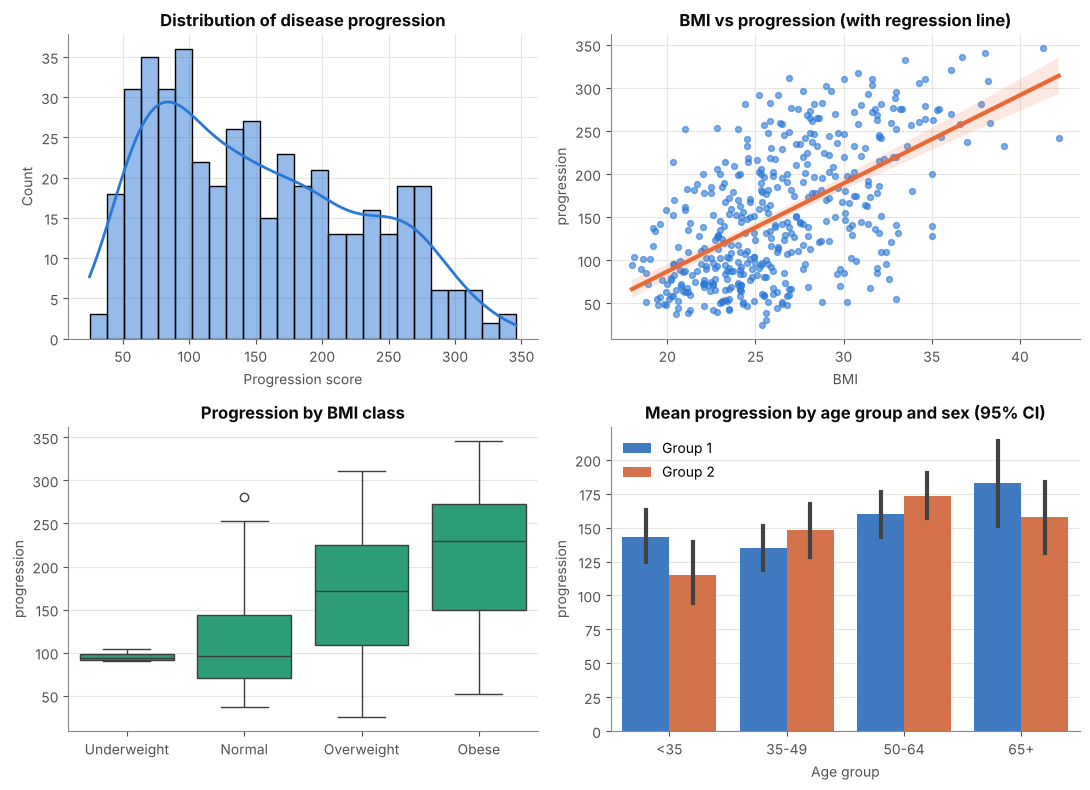

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
sns.histplot(df, x="progression", bins=25, kde=True, color=BLUE, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of disease progression"); axes[0, 0].set_xlabel("Progression score")

sns.regplot(df, x="bmi", y="progression", scatter_kws={"s": 18, "color": BLUE, "alpha": 0.6},
            line_kws={"color": ORANGE}, ax=axes[0, 1])
axes[0, 1].set_title("BMI vs progression (with regression line)"); axes[0, 1].set_xlabel("BMI")

order = ["Underweight", "Normal", "Overweight", "Obese"]
sns.boxplot(features, x="bmi_class", y="progression", order=[o for o in order if o in features.bmi_class.unique()],
            color=AQUA, ax=axes[1, 0])
axes[1, 0].set_title("Progression by BMI class"); axes[1, 0].set_xlabel("")

sns.barplot(features, x="age_group", y="progression", hue="sex", hue_order=["Group 1", "Group 2"], palette=[BLUE, ORANGE],
            errorbar=("ci", 95), ax=axes[1, 1])
axes[1, 1].set_title("Mean progression by age group and sex (95% CI)"); axes[1, 1].set_xlabel("Age group")
axes[1, 1].legend(title="")
plt.tight_layout()
plt.savefig("figures/01_chart_gallery.png", dpi=150, bbox_inches="tight")

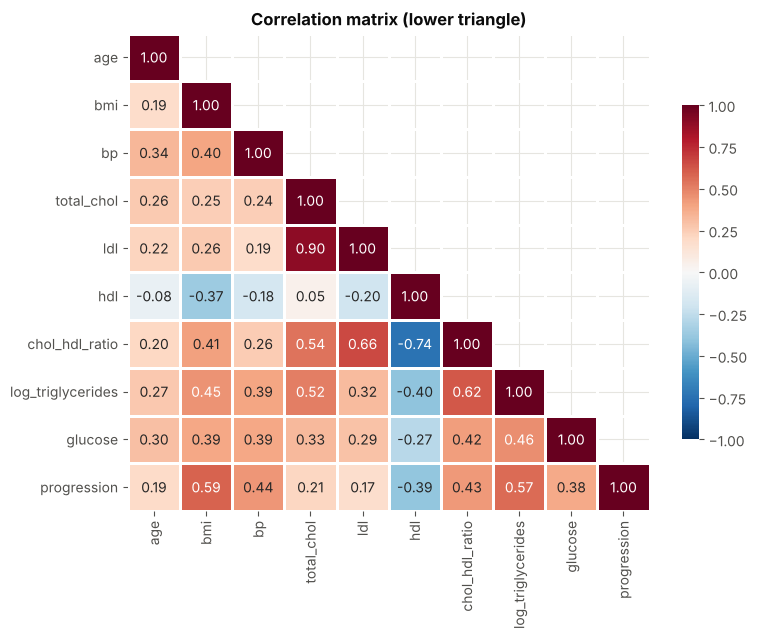

In [7]:
num = df.drop(columns="sex")
fig, ax = plt.subplots(figsize=(8, 6.5))
mask = np.triu(np.ones_like(num.corr(), dtype=bool), k=1)
sns.heatmap(num.corr(), mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=1, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation matrix (lower triangle)")
plt.tight_layout()
plt.savefig("figures/02_correlation_heatmap.png", dpi=150, bbox_inches="tight")

## Tool 5 — SciPy: statistical testing

In [8]:
r, p = stats.pearsonr(df.bmi, df.progression)
rho, p_s = stats.spearmanr(df.glucose, df.progression)
g1, g2 = df[df.sex == "Group 1"].progression, df[df.sex == "Group 2"].progression
t, p_t = stats.ttest_ind(g1, g2, equal_var=False)
table = pd.crosstab(features.bp_high, features.risk_quartile == "Q4 high")
chi2, p_c, dof, _ = stats.chi2_contingency(table)
F, p_a = stats.f_oneway(*[g.progression for _, g in features.groupby("bmi_class", observed=True)])

results = pd.DataFrame([
    ["BMI vs progression", "Pearson r", r, p],
    ["Glucose vs progression", "Spearman rho", rho, p_s],
    ["Progression: sex Group 1 vs Group 2", "Welch t", t, p_t],
    ["High BP vs top-quartile progression", "Chi-square", chi2, p_c],
    ["Progression across BMI classes", "ANOVA F", F, p_a],
], columns=["Question", "Test", "Statistic", "p-value"])
results["Significant (5%)"] = results["p-value"] < 0.05
display(results.round(4))

,Question,Test,Statistic,p-value,Significant (5%)
0,BMI vs progression,Pearson r,0.5865,0.0000,True
1,Glucose vs progression,Spearman rho,0.3508,0.0000,True
2,Progression: sex Group 1 vs Group 2,Welch t,-0.9022,0.3674,False
3,High BP vs top-quartile progression,Chi-square,70.3653,0.0000,True
4,Progression across BMI classes,ANOVA F,57.3511,0.0000,True


## Tool 6 — scikit-learn: pipelines, cross-validation and model comparison

In [9]:
X = pd.get_dummies(df.drop(columns="progression"), columns=["sex"], drop_first=True, dtype=float)
y = df["progression"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

models = {
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
    "Ridge (alpha=10)": Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=10))]),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE),
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    cv_r2 = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append([name, cv_r2.mean(), cv_r2.std(), r2_score(y_test, pred),
                 mean_absolute_error(y_test, pred), mean_squared_error(y_test, pred) ** 0.5])
scores = pd.DataFrame(rows, columns=["Model", "CV R² mean", "CV R² std", "Test R²", "Test MAE", "Test RMSE"])
display(scores.round(3))
scores.to_csv("output/model_comparison.csv", index=False)

,Model,CV R² mean,CV R² std,Test R²,Test MAE,Test RMSE
0,Linear Regression,0.480,0.041,0.453,42.794,53.853
1,Ridge (alpha=10),0.480,0.039,0.457,42.857,53.626
2,Random Forest,0.431,0.067,0.458,43.402,53.584
3,Gradient Boosting,0.424,0.035,0.472,42.820,52.893


Top positive drivers: ['bmi', 'log_triglycerides', 'bp']


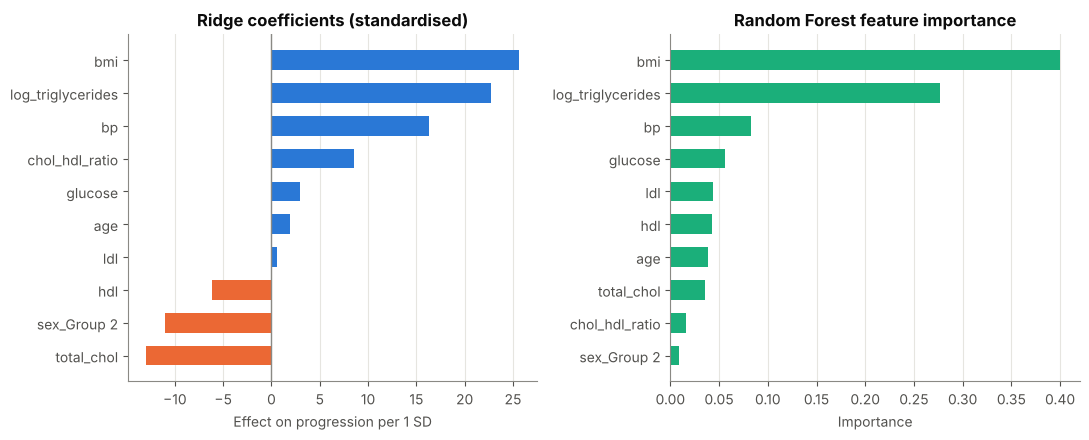

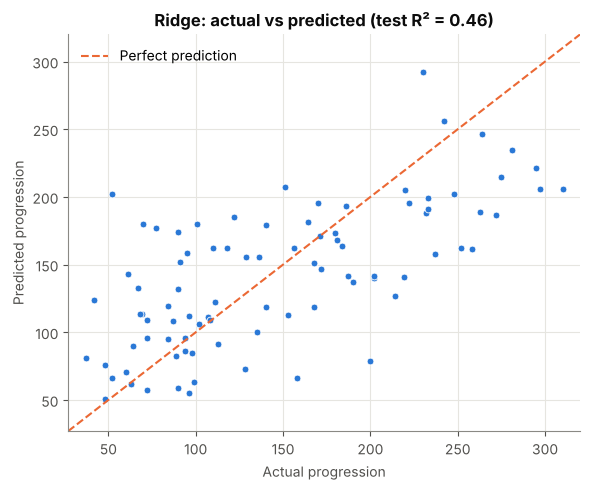

In [10]:
best = models["Ridge (alpha=10)"]
coefs = pd.Series(best.named_steps["model"].coef_, index=X.columns).sort_values()
rf_imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(coefs.index, coefs.values, color=[ORANGE if v < 0 else BLUE for v in coefs.values], height=0.6)
axes[0].axvline(0, color="#8a8984", linewidth=1)
axes[0].set_title("Ridge coefficients (standardised)"); axes[0].set_xlabel("Effect on progression per 1 SD")
axes[1].barh(rf_imp.index, rf_imp.values, color=AQUA, height=0.6)
axes[1].set_title("Random Forest feature importance"); axes[1].set_xlabel("Importance")
for a in axes: a.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("figures/03_feature_effects.png", dpi=150, bbox_inches="tight")

pred = best.predict(X_test)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, pred, s=24, color=BLUE, edgecolor="white", linewidth=0.6)
lims = [min(y_test.min(), pred.min()) - 10, max(y_test.max(), pred.max()) + 10]
ax.plot(lims, lims, color=ORANGE, linestyle="--", linewidth=1.5, label="Perfect prediction")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual progression"); ax.set_ylabel("Predicted progression")
ax.set_title(f"Ridge: actual vs predicted (test R² = {r2_score(y_test, pred):.2f})")
ax.legend()
plt.tight_layout()
plt.savefig("figures/04_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
print("Top positive drivers:", list(coefs.tail(3).index[::-1]))

## Tool 7 — Excel automation with openpyxl (portfolio piece)
A formatted, multi-sheet Excel report is generated automatically — with live Excel formulas, conditional formatting and a native Excel chart.

In [11]:
path = kit.build_excel_report(features, scores, results, "output/Diabetes_Analysis_Report.xlsx")
from openpyxl import load_workbook
wb = load_workbook(path)
print("Sheets:", wb.sheetnames)
print("Example formula in Summary!C4:", wb["Summary"]["C4"].value)

Sheets: ['Summary', 'Data', 'Models', 'Statistical tests']
Example formula in Summary!C4: =AVERAGEIF(Data!$G$2:$G$443,A4,Data!$F$2:$F$443)


## Tool 8 — Git and GitHub workflow
```bash
git init
git add task4-data-science-tool-mastery/
git commit -m "Task 4: tool mastery notebook, SQL queries, Excel report"
git branch -M main
git remote add origin https://github.com/<username>/yuvaintern-data-analyst.git
git push -u origin main
```
Good habits used: small focused commits with clear messages, a README in every folder, `requirements.txt` for dependencies, and generated files kept in clearly named folders.

## Summary
- **NumPy:** vectorised code gave identical results and was much faster than a Python loop.
- **Pandas:** method chaining created five new features in one readable block.
- **SQL:** four queries (GROUP BY, CASE + HAVING, window RANK, sub-query) matched the Pandas results exactly.
- **Seaborn/Matplotlib:** a 4-panel gallery, heatmap and model charts.
- **SciPy:** BMI, glucose, BMI class and blood pressure are significantly linked to progression; sex is not.
- **scikit-learn:** Ridge regression had the best cross-validated R² (0.48) and a test R² of 0.46; the tree models were not reliably better. BMI, log-triglycerides and blood pressure are the strongest drivers.
- **openpyxl:** a ready-to-share Excel report with formulas, formatting and a chart.